# Regresión lineal múltiple y Ridge, árboles de decisión y random forest

Ejemplo para el curso de Inteligencia Artificial. Adaptado del ejemplo de https://github.com/krishnaik06/Multiple-Linear-Regression.

## 1. Descripción del problema y objetivo

Una empresa desea estimar las ganancias (Profit) de una startup a partir de sus gastos en investigación y desarrollo (R&D Spend), administración (Administration), marketing (Marketing Spend) y su ubicación (State). Cada fila del conjunto de datos 50_Startups representa una empresa.

Objetivo: construir y comparar dos modelos de regresión, y árboles de decisión, incluyendo random forest, para predecir Profit. Se evaluarán con datos que no se utilizaron para entrenarlos.

Las relaciones identificadas permiten hacer predicciones; no demuestran que un gasto cause directamente un cambio en las ganancias. El conjunto de datos es pequeño (50 empresas), por lo que sus resultados deben interpretarse con cautela.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 2.Inspección inicial del conjunto de datos

Antes de entrenar cualquier modelo se revisan las dimensiones, los tipos de datos, las estadísticas descriptivas y la calidad básica de los registros.

In [2]:
df = pd.read_csv("50_Startups.csv")
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (50, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [3]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
R&D Spend,50.0,NaN,NaN,NaN,73721.6156,45902.256482,0.0,39936.37,73051.08,101602.8,165349.2
Administration,50.0,NaN,NaN,NaN,121344.6396,28017.802755,51283.14,103730.875,122699.795,144842.18,182645.56
Marketing Spend,50.0,NaN,NaN,NaN,211025.0978,122290.310726,0.0,129300.1325,212716.24,299469.085,471784.1
State,50,3,New York,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,50.0,NaN,NaN,NaN,112012.6392,40306.180338,14681.4,90138.9025,107978.19,139765.9775,192261.83


### 2.1 Valores faltantes y registros duplicados

Se inspeccionan los valores ausentes y las filas repetidas. Si se encuentran registros problemáticos, conviene revisar su origen antes de eliminarlos o reemplazarlos.

In [5]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores faltantes por columna:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

Filas duplicadas: 0


El conjunto de datos contiene 50 registros de empresas y 5 variables. De estas, cuatro son numéricas (R&D Spend, Administration, Marketing Spend y Profit) y una es categórica (State), que presenta tres categorías: New York, California y Florida. La variable objetivo es Profit, mientras que las demás se utilizarán como variables predictoras.

El resultado de la función describe muestra diferencias importantes en las escalas y la dispersión de las variables numéricas. Por ejemplo, el gasto promedio en marketing es de aproximadamente 211.025, mientras que el gasto promedio en investigación y desarrollo es de 73.722. Las ganancias presentan un promedio de 112.013 y varían entre 14.681 y 192.262. También se observan valores mínimos de cero en los gastos de investigación y desarrollo y marketing, que conviene examinar posteriormente.

No se identificaron valores faltantes ni registros duplicados.

## 3. Exploración de la variable a predecir y las variables predictoras

La variable objetivo es Profit. Las variables numéricas predictoras son R&D Spend, Administration y Marketing Spend. State es categórica.

### 3.1 Distribución de la variable objetivo

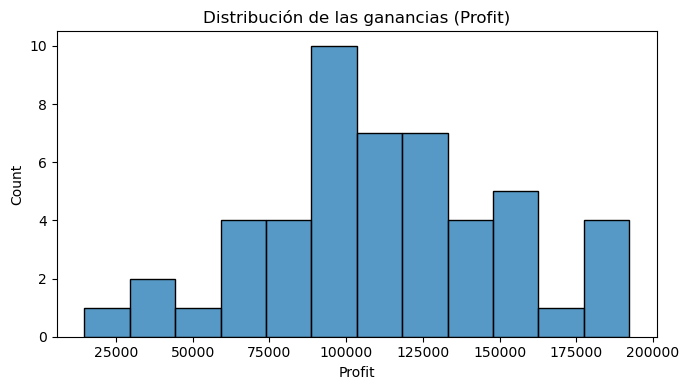

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Profit", bins=12)
plt.title("Distribución de las ganancias (Profit)")
plt.tight_layout()
plt.show()

### 3.2 Distribución de las variables predictoras

Para las variables numéricas se utilizan histogramas. Para State se utiliza un diagrama de barras con el número de empresas por estado.

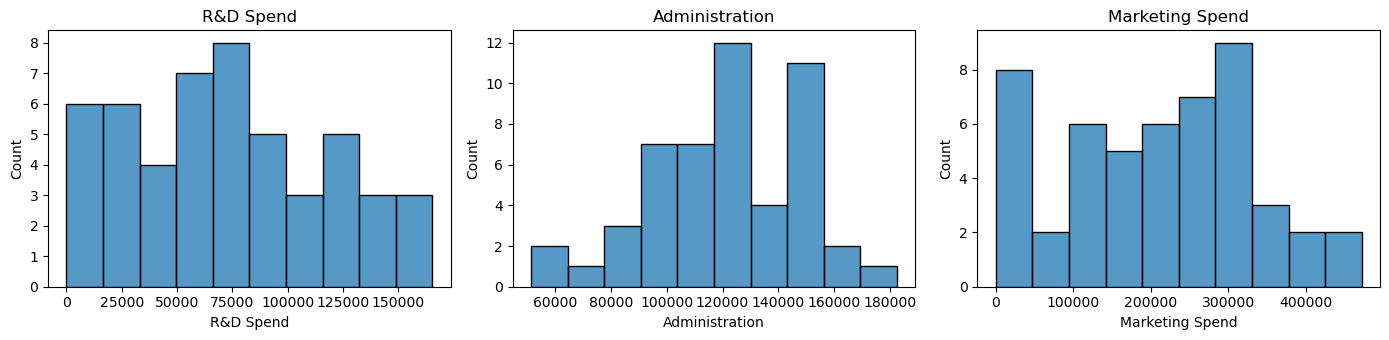

In [7]:
variables_numericas = ["R&D Spend", "Administration", "Marketing Spend"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, variable in zip(axes, variables_numericas):
    sns.histplot(data=df, x=variable, bins=10, ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

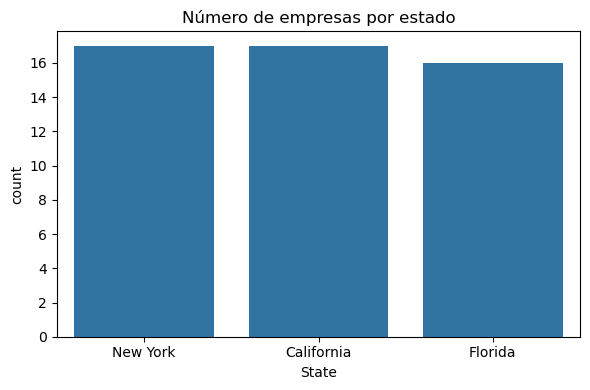

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="State")
plt.title("Número de empresas por estado")
plt.tight_layout()
plt.show()

### 3.3 Inspección de posibles valores atípicos

Los diagramas de cajas ayudan a detectar observaciones inusuales. Un valor señalado como atípico no es necesariamente incorrecto y no debe eliminarse automáticamente.

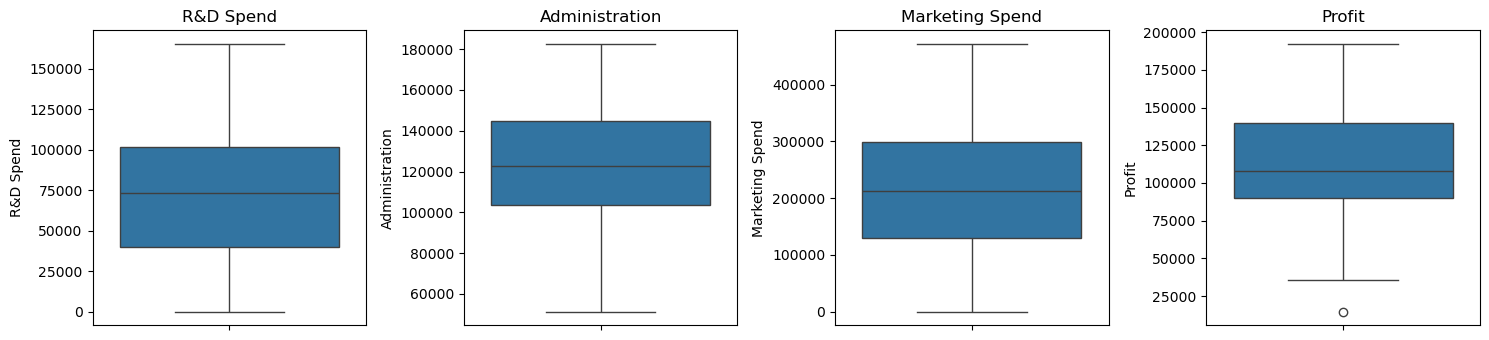

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, variable in zip(axes, variables_numericas + ["Profit"]):
    sns.boxplot(y=df[variable], ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

### 3.4 Correlación entre variables numéricas

Se utiliza la correlación de Pearson para explorar relaciones lineales, especialmente entre variables predictoras. Una correlación elevada entre predictores puede indicar multicolinealidad. La matriz sirve para explorar los datos, no para demostrar causalidad.

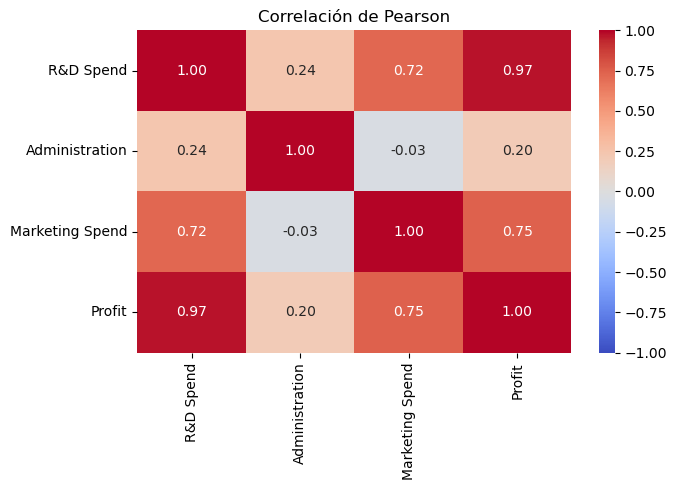

In [10]:
columnas_numericas = variables_numericas + ["Profit"]
correlaciones = df[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.tight_layout()
plt.show()

Los histogramas muestran que las ganancias (Profit) se concentran principalmente entre 90.000 y 140.000, aunque existen empresas con ganancias considerablemente menores o mayores. Las variables predictoras presentan distribuciones diferentes: R&D Spend y Marketing Spend muestran una dispersión amplia, incluyendo empresas con gastos iguales o cercanos a cero, mientras que Administration presenta una mayor concentración alrededor de sus valores centrales.

Los diagramas de cajas permiten identificar un posible valor atípico en la variable Profit, correspondiente a una empresa con ganancias particularmente bajas. Sin embargo, esta observación no debe eliminarse sin verificar previamente si corresponde a un error o a un caso válido.

El análisis de correlación de Pearson muestra que R&D Spend presenta la relación lineal más fuerte con Profit (r = 0.97), seguida de Marketing Spend (r = 0.75). Por el contrario, Administration presenta una correlación positiva débil con las ganancias (r = 0.20). Esto sugiere que los gastos en investigación y desarrollo podrían tener una mayor capacidad predictiva, aunque la correlación por sí sola no permite establecer relaciones causales ni determinar la contribución de cada variable en un modelo múltiple.

## 4. Preparación de datos

Se separan las variables predictoras de la variable objetivo y se reservan el 20 % de las empresas para prueba. El conjunto de prueba no se utiliza para ajustar el escalamiento ni para seleccionar hiperparámetros.

En este ejemplo no se realizará reducción ni selección de características: solo hay tres predictores numéricos y una variable categórica, y no se ha encontrado una justificación suficiente para eliminar alguno. La matriz de correlación por sí sola no obliga a descartar predictores.

In [11]:
X = df[variables_numericas + ["State"]].copy()
y = df["Profit"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)
print("Ejemplos de entrenamiento:", len(X_train))
print("Ejemplos de prueba:", len(X_test))

Ejemplos de entrenamiento: 40
Ejemplos de prueba: 10


### 4.1 Codificación de la variable categórica State

Los modelos de regresión requieren valores numéricos. Se convierten los estados en variables indicadoras (0 o 1); se omite una categoría de referencia para evitar una redundancia perfecta con el intercepto. Se definen las categorías con el conjunto de entrenamiento y se utiliza la misma estructura de columnas al transformar la prueba.

In [12]:
X_train_cod = pd.get_dummies(X_train, columns=["State"], dtype=int)
X_test_cod = pd.get_dummies(X_test, columns=["State"], dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

X_train_cod.head()
print(X_train_cod.head())

    R&D Spend  Administration  Marketing Spend  State_California  \
33   55493.95       103057.49        214634.81                 0   
35   46014.02        85047.44        205517.64                 0   
26   75328.87       144135.98        134050.07                 0   
34   46426.07       157693.92        210797.67                 1   
18   91749.16       114175.79        294919.57                 0   

    State_Florida  State_New York  
33              1               0  
35              0               1  
26              1               0  
34              0               0  
18              1               0  


### 4.2 Estandarización de las variables numéricas

StandardScaler resta la media y divide por la desviación estándar. Se ajusta únicamente con las observaciones de entrenamiento y luego se aplica a entrenamiento y prueba. Solo se escalan las tres variables de gasto; las columnas de State permanecen como 0 o 1. Esta estandarización es especialmente útil para comparar el efecto de la regularización de Ridge.

In [13]:
scaler = StandardScaler()
X_train_preparado = X_train_cod.copy()
X_test_preparado = X_test_cod.copy()

X_train_preparado[variables_numericas] = scaler.fit_transform(X_train_cod[variables_numericas])
X_test_preparado[variables_numericas] = scaler.transform(X_test_cod[variables_numericas])

X_train_preparado.head()

,R&D Spend,Administration,Marketing Spend,State_California,State_Florida,State_New York
33,-0.350065,-0.785471,0.101197,0,1,0
35,-0.555303,-1.481174,0.027350,0,0,1
26,0.079358,0.801334,-0.551521,0,1,0
34,-0.546382,1.325058,0.070117,1,0,0
18,0.434854,-0.355987,0.751485,0,1,0


## 5. Implementación base del modelo de regresión lineal múltiple

LinearRegression estima los coeficientes que minimizan la suma de errores cuadrados en los datos de entrenamiento.

In [14]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_preparado, y_train)

print("Intercepto:", modelo_lineal.intercept_)
print("\nCoeficientes:")
print(pd.Series(modelo_lineal.coef_, index=X_train_preparado.columns))

Intercepto: 109354.85075245326

Coeficientes:
R&D Spend           35726.287742
Administration        851.301634
Marketing Spend      4519.882777
State_California       86.638369
State_Florida        -872.645791
State_New York        786.007422
dtype: float64


### 5.1 Evaluación con el conjunto de prueba

Se calculan R², MAE y RMSE. MAE y RMSE se expresan en las mismas unidades de Profit; cuanto menores sean, mejor. R² puede ser negativo cuando el modelo funciona peor que predecir una constante igual a la media de la prueba.

In [15]:
def evaluar_modelo(valores_reales, predicciones):
    mae = mean_absolute_error(valores_reales, predicciones)
    rmse = np.sqrt(mean_squared_error(valores_reales, predicciones))

    rango = np.max(valores_reales) - np.min(valores_reales)

    return {"R2": r2_score(valores_reales, predicciones), "MAE": mae, "RMSE": rmse,
            "MAPE": mean_absolute_percentage_error(valores_reales, predicciones),
            "NMAE": mae / rango if rango > 0 else np.nan,
            "NRMSE": rmse / rango if rango > 0 else np.nan}

In [16]:
pred_lineal = modelo_lineal.predict(X_test_preparado)
metricas_lineal = evaluar_modelo(y_test, pred_lineal)
print(pd.Series(metricas_lineal).round(2))

R2          0.93
MAE      7514.29
RMSE     9137.99
MAPE        0.06
NMAE        0.07
NRMSE       0.08
dtype: float64


## 6. Implementación del modelo de regresión Ridge

Ridge es una regresión lineal que añade una penalización sobre el tamaño de los coeficientes. El hiperparámetro alpha controla la intensidad de la regularización: cuanto mayor sea, mayor será la penalización.

Para mantener la práctica sencilla, se entrenará Ridge con alpha=1. Este valor es ilustrativo: no se afirma que sea el óptimo. Si se prueban varios valores de alpha, no debe escogerse el mejor según el conjunto de prueba porque se dejaría de disponer de una evaluación independiente.

In [17]:
modelo_ridge = Ridge(alpha=1.0)
modelo_ridge.fit(X_train_preparado, y_train)

pred_ridge = modelo_ridge.predict(X_test_preparado)
metricas_ridge = evaluar_modelo(y_test, pred_ridge)
print(pd.Series(metricas_ridge).round(2))

R2          0.92
MAE      8018.49
RMSE     9947.36
MAPE        0.07
NMAE        0.07
NRMSE       0.09
dtype: float64


In [39]:
df_coef = pd.DataFrame({"Variable": X_train_preparado.columns, "Lineal": modelo_lineal.coef_, 
                        "Ridge": modelo_ridge.coef_})
print(df_coef.round(4))

           Variable      Lineal       Ridge
0         R&D Spend  35726.2877  33775.5633
1    Administration    851.3016   1389.1078
2   Marketing Spend   4519.8828   5747.0010
3  State_California     86.6384    -32.0900
4     State_Florida   -872.6458  -1094.8754
5    State_New York    786.0074   1126.9654


In [40]:
print("Norma L2 regresión lineal:", np.linalg.norm(modelo_lineal.coef_))
print("Norma L2 Ridge:", np.linalg.norm(modelo_ridge.coef_))

Norma L2 regresión lineal: 36040.37340539191
Norma L2 Ridge: 34325.15328999962


Al comparar los coeficientes de la regresión lineal sin regularización con los obtenidos mediante Ridge (alpha=1.0), se observa que la regularización no necesariamente reduce la magnitud de cada coeficiente individualmente; algunos incluso pueden aumentar. El efecto de shrinkage se evidencia en la reducción de la norma L2 del vector de coeficientes, que pasó de 36040.37 en la regresión lineal a 34325.15 en Ridge, lo que representa una disminución del 4.76 %. 

# 7. Comparación de los resultados

En esta sección se comparan los resultados de la regresión lineal múltiple y la regresión Ridge utilizando el conjunto de prueba.

Para Ridge se utiliza alpha= 1.0 que es el valor por defecto en Sickit-Learn. Ambos modelos se evaluarán utilizando las mismas observaciones de prueba y las métricas R², MAE y RMSE.

In [19]:
# Comparación con la regresión lineal
comparacion = pd.DataFrame([metricas_lineal, metricas_ridge], index=["Regresión lineal", "Ridge (alpha=1.0)"])
comparacion.round(2)

,R2,MAE,RMSE,MAPE,NMAE,NRMSE
Regresión lineal,0.93,7514.29,9137.99,0.06,0.07,0.08
Ridge (alpha=1.0),0.92,8018.49,9947.36,0.07,0.07,0.09


### 7.1 Valores reales frente a predichos

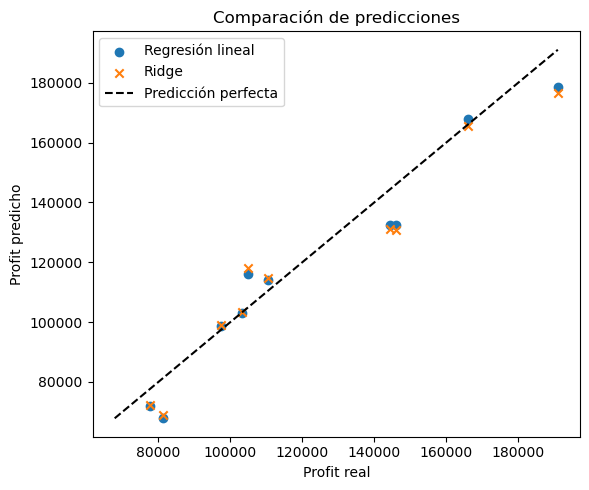

In [49]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_lineal, label="Regresión lineal")
plt.scatter(y_test, pred_ridge, label="Ridge", marker="x")
limites = [min(y_test.min(), pred_lineal.min(), pred_ridge.min()),
           max(y_test.max(), pred_lineal.max(), pred_ridge.max())]
plt.plot(limites, limites, "k--", label="Predicción perfecta")
plt.xlabel("Profit real")
plt.ylabel("Profit predicho")
plt.title("Comparación de predicciones")
plt.legend()
plt.tight_layout()
plt.show()

En un modelo perfecto los puntos quedarían sobre la línea punteada. En la gráfica se puede observar que los resultados del modelo lineal coinciden bastante con los resultados del modelo Ridge. En algunos casos ambos modelos generaron soluciones cercanas al valor real.

Ahora, se representan mediante gráficas de líneas los valores reales de Profit de las empresas del conjunto de prueba y los valores predichos por los modelos de regresión lineal y Ridge. El objetivo es observar visualmente qué tan próximas se encuentran las predicciones de ambos modelos a los valores reales e identificar aquellas observaciones donde presentan mayores errores.

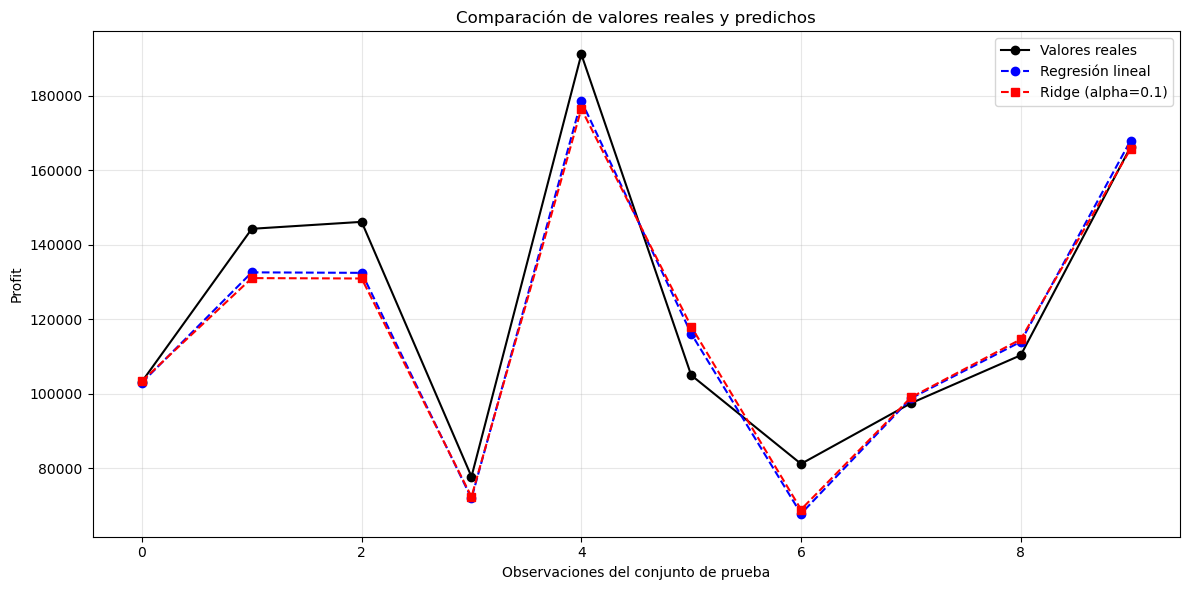

In [48]:
X = np.arange(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(X, np.array(y_test), 'k-o',label='Valores reales')
plt.plot(X, pred_lineal, 'b--o', label='Regresión lineal')
plt.plot(X, pred_ridge, 'r--s',label='Ridge (alpha=0.1)')
plt.xlabel('Observaciones del conjunto de prueba')
plt.ylabel('Profit')
plt.title('Comparación de valores reales y predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Evalúemos si hay posible sobreajuste

In [41]:
pred_lineal_train = modelo_lineal.predict(X_train_preparado)
metricas_lineal_train = evaluar_modelo(y_train, pred_lineal_train)
print(pd.Series(metricas_lineal_train).round(2))

R2          0.95
MAE      6341.54
RMSE     9031.67
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64


In [44]:
pred_ridge_train = modelo_ridge.predict(X_train_preparado)
metricas_ridge_train = evaluar_modelo(y_train, pred_ridge_train)
print(pd.Series(metricas_ridge_train).round(2))

R2          0.95
MAE      6383.95
RMSE     9110.84
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64


In [45]:
tabla_metricas = pd.DataFrame({
    "Lineal - Entrenamiento": metricas_lineal_train,
    "Lineal - Prueba": metricas_lineal,
    "Ridge - Entrenamiento": metricas_ridge_train,
    "Ridge - Prueba": metricas_ridge
})

display(tabla_metricas.round(2))

,Lineal - Entrenamiento,Lineal - Prueba,Ridge - Entrenamiento,Ridge - Prueba
R2,0.95,0.93,0.95,0.92
MAE,6341.54,7514.29,6383.95,8018.49
RMSE,9031.67,9137.99,9110.84,9947.36
MAPE,0.12,0.06,0.12,0.07
NMAE,0.04,0.07,0.04,0.07
NRMSE,0.05,0.08,0.05,0.09


Los modelos de regresión lineal y Ridge presentan una ligera disminución de su desempeño predictivo al pasar del conjunto de entrenamiento al conjunto de prueba. Sin embargo, las diferencias en R² son pequeñas (0.02 y 0.03, respectivamente), por lo que no se puede asegurar que sea un caso de sobreajuste significativo. Ambos modelos mantienen una buena capacidad de generalización. Adicionalmente, aunque la regularización Ridge redujo la norma L2 de los coeficientes, no produjo una mejora en el desempeño predictivo respecto a la regresión lineal ordinaria.

## 8. Implementación base de un modelo arbol de decisión

In [51]:
modelo_arbol1 = DecisionTreeRegressor()

modelo_arbol1.fit(X_train_preparado, y_train)
pred_arbol1 = modelo_arbol1.predict(X_test_preparado)

metricas_tree1 = evaluar_modelo(y_test, pred_arbol1)
print(pd.Series(metricas_tree1).round(2))

R2          0.98
MAE      4480.29
RMSE     5489.04
MAPE        0.04
NMAE        0.04
NRMSE       0.05
dtype: float64


Evaluemos enseguida si hubo sobreajuste:

In [52]:
pred_arbol1_train = modelo_arbol1.predict(X_train_preparado)
metricas_tree1_train = evaluar_modelo(y_train, pred_arbol1_train)
print(pd.Series(metricas_tree1_train).round(2))

R2       1.0
MAE      0.0
RMSE     0.0
MAPE     0.0
NMAE     0.0
NRMSE    0.0
dtype: float64


De acuerdo a estos resultados estamos frente a un caso de posible sobreajuste, corroboremos con una representación gráfica del árbol.

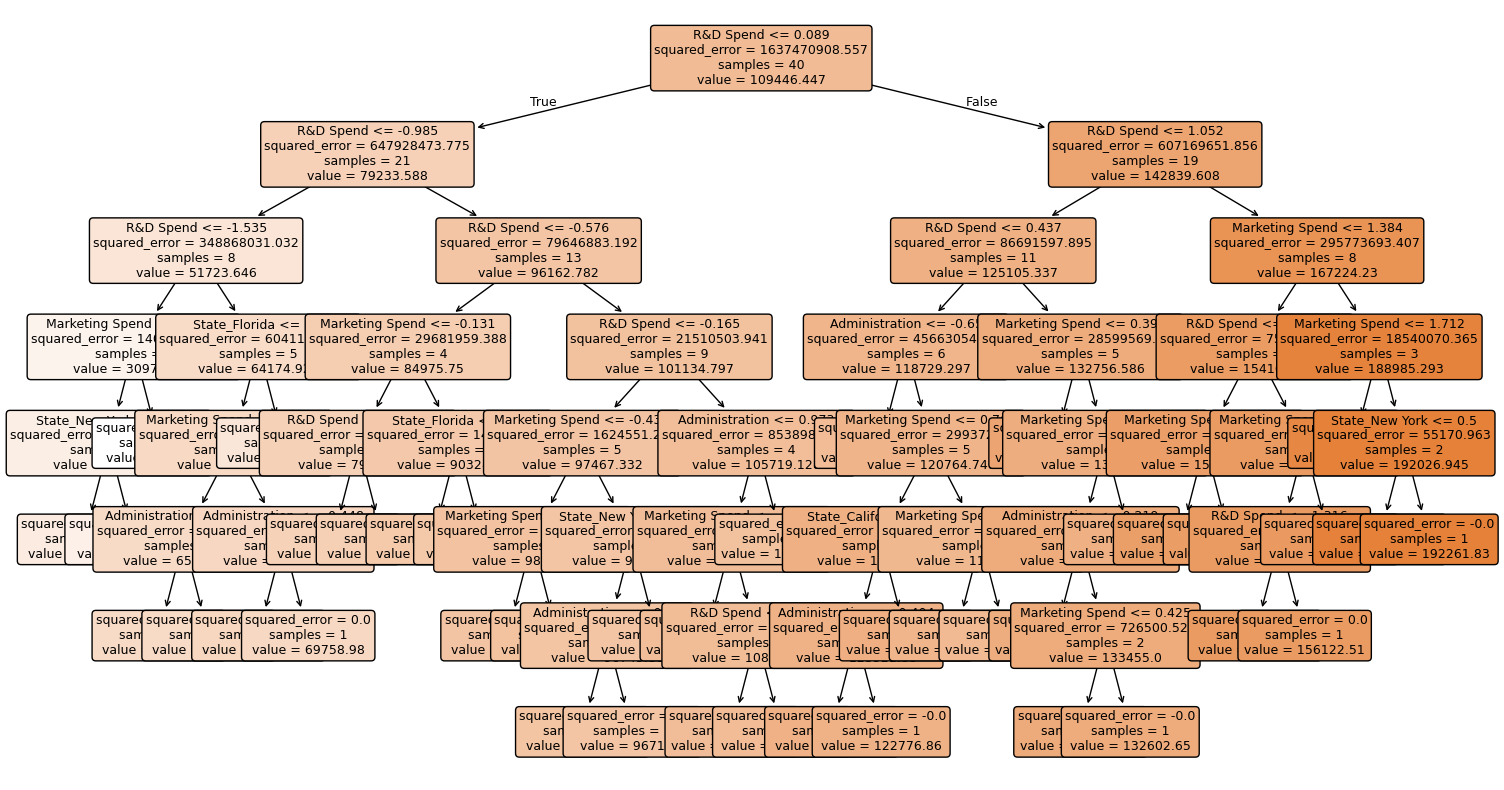

In [53]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_arbol1, feature_names=X_train_preparado.columns, filled=True, rounded=True, fontsize=9)
plt.show()

In [54]:
es_hoja = modelo_arbol1.tree_.children_left == -1

# Número de observaciones en cada hoja
muestras_por_hoja = modelo_arbol1.tree_.n_node_samples[es_hoja]

# Cantidad de hojas con una sola observación
hojas_una_muestra = np.sum(muestras_por_hoja == 1)

print("Número total de hojas:", modelo_arbol1.get_n_leaves())
print("Hojas con una sola observación:", hojas_una_muestra)
print("Porcentaje:", round(100 * hojas_una_muestra / modelo_arbol1.get_n_leaves(), 2), "%")

Número total de hojas: 40
Hojas con una sola observación: 40
Porcentaje: 100.0 %


El 100% de las hojas del árbol contienen solo 1 ejemplo, lo cuál confirma el indicio de que el modelo está sobreajustado.

### 8.1 Utilicemos hiperparámetros para tratar de evitar el sobreajuste

In [73]:
modelo_arbol2 = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=42)

modelo_arbol2.fit(X_train_preparado, y_train)

pred_arbol2_train = modelo_arbol2.predict(X_train_preparado)
pred_arbol2 = modelo_arbol2.predict(X_test_preparado)

print("Resultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_arbol2_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(evaluar_modelo(y_test, pred_arbol2)).round(2))

print("\nProfundidad:", modelo_arbol2.get_depth())
print("Número de hojas:", modelo_arbol2.get_n_leaves())

Resultados entrenamiento:
R2           0.91
MAE       9501.50
RMSE     12214.66
MAPE         0.15
NMAE         0.05
NRMSE        0.07
dtype: float64

Resultados prueba:
R2           0.85
MAE      10643.97
RMSE     13949.48
MAPE         0.10
NMAE         0.09
NRMSE        0.12
dtype: float64

Profundidad: 3
Número de hojas: 6


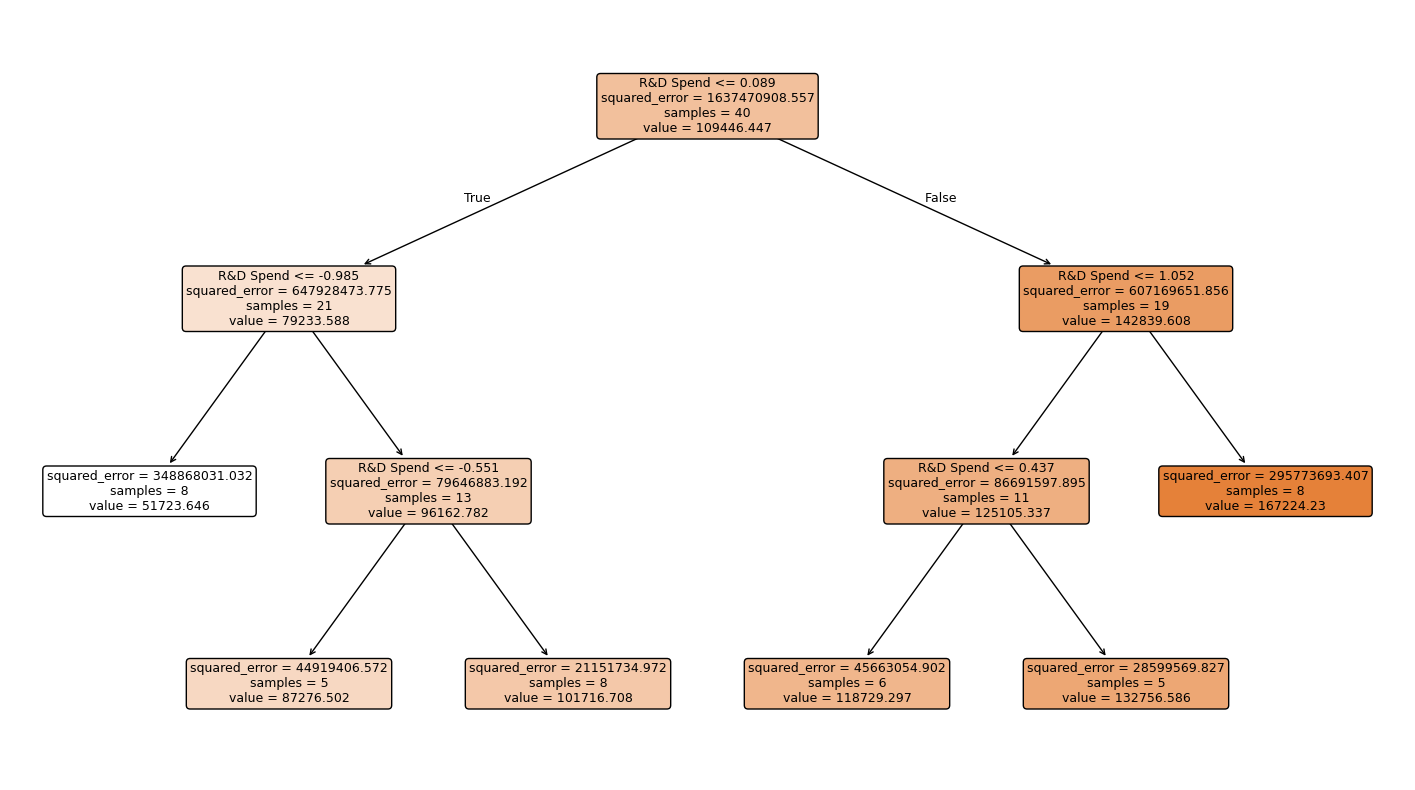

In [57]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_arbol2, feature_names=X_train_preparado.columns, filled=True, rounded=True, fontsize=9)
plt.show()

## 9. Implementación base de un modelo Random Forest

In [59]:
modelo_rf1 = RandomForestRegressor()
modelo_rf1.fit(X_train_preparado, y_train)

pre_rf1 = modelo_rf1.predict(X_test_preparado)

metricas_rf1 = evaluar_modelo(y_test, predicciones)
print(pd.Series(metricas_rf1).round(2))

R2           0.89
MAE       7721.32
RMSE     12094.45
MAPE         0.06
NMAE         0.07
NRMSE        0.11
dtype: float64


Evalúemos si hay sobreajuste

In [60]:
pred_trainRF1 = modelo_rf1.predict(X_train_preparado)

metricas_trainRF1 = evaluar_modelo(y_train, pred_trainRF1)
print(pd.Series(metricas_trainRF1).round(2))

R2          0.99
MAE      3486.87
RMSE     4417.30
MAPE        0.06
NMAE        0.02
NRMSE       0.02
dtype: float64


In [61]:
def revisa_RF(modelo):
   resultados_arboles = []
   for i, arbol in enumerate(modelo.estimators_):

      # Identificar las hojas
      es_hoja = arbol.tree_.children_left == -1

      # Número de observaciones por hoja
      muestras_por_hoja = arbol.tree_.n_node_samples[es_hoja]

      # Porcentaje de hojas con una observación
      porcentaje = 100 * np.mean(muestras_por_hoja == 1)

      resultados_arboles.append({"Arbol": i + 1, "Profundidad": arbol.get_depth(),
                               "Numero_hojas": arbol.get_n_leaves(), "Porcentaje_hojas_1": porcentaje})
      df_arboles = pd.DataFrame(resultados_arboles)
   print(df_arboles.round(2))
   return df_arboles

In [62]:
df_arboles = revisa_RF(modelo_rf1)
print("Árboles con el 100% de hojas individuales:", (df_arboles["Porcentaje_hojas_1"] == 100).sum())

    Arbol  Profundidad  Numero_hojas  Porcentaje_hojas_1
0       1            7            27               100.0
1       2            7            26               100.0
2       3            6            24               100.0
3       4            7            27               100.0
4       5            7            29               100.0
..    ...          ...           ...                 ...
95     96            6            29               100.0
96     97            8            29               100.0
97     98            7            22               100.0
98     99            7            26               100.0
99    100            8            28               100.0

[100 rows x 4 columns]
Árboles con el 100% de hojas individuales: 100


Al parecer el modelo está sobreajustado vamos a utilizar algunos hiperparámetros tratando de evitar el sobreajueste

In [63]:
modelo_rf2 = RandomForestRegressor(n_estimators=100,  max_depth=10, min_samples_leaf=5, min_samples_split=10, random_state=42)

modelo_rf2.fit(X_train_preparado, y_train)

pred_rf2 = modelo_rf2.predict(X_test_preparado)
metricas_rf2 = evaluar_modelo(y_test, pred_rf2)
print(pd.Series(metricas_rf2).round(2))

R2           0.89
MAE       7721.32
RMSE     12094.45
MAPE         0.06
NMAE         0.07
NRMSE        0.11
dtype: float64


In [64]:
pred_trainRF2 = modelo_rf2.predict(X_train_preparado)

metricas_trainRF2 = evaluar_modelo(y_train, pred_trainRF2)
print(pd.Series(metricas_trainRF2).round(2))

R2           0.91
MAE       8429.60
RMSE     11797.97
MAPE         0.15
NMAE         0.05
NRMSE        0.07
dtype: float64


In [65]:
df_arboles2 = revisa_RF(modelo_rf2)
print("Árboles con el 100% de hojas individuales:", (df_arboles2["Porcentaje_hojas_1"] == 100).sum())

    Arbol  Profundidad  Numero_hojas  Porcentaje_hojas_1
0       1            2             4                 0.0
1       2            3             4                 0.0
2       3            3             4                 0.0
3       4            3             4                 0.0
4       5            3             4                 0.0
..    ...          ...           ...                 ...
95     96            3             5                 0.0
96     97            2             4                 0.0
97     98            2             4                 0.0
98     99            3             5                 0.0
99    100            3             4                 0.0

[100 rows x 4 columns]
Árboles con el 100% de hojas individuales: 0


## 10. Comparación de modelos basados en árboles y regresion lineal

De los modelos bases y primeros experimentos seleccionamos Regresión Lineal, porque generó mejor resultado que la Regresión Ridge, y los modelos de Árbol de decisión y Random Forest que entrenamos con hiperparámetros porque las primeras pruebas generaron modelos sobreajustados. Vamos a ver comparaciones gráficas de estos resultados y al final una comparación en términos de las métricas.

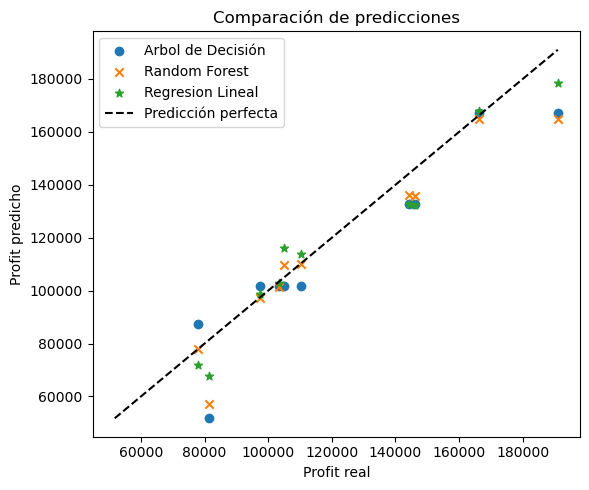

In [70]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_arbol2, label="Arbol de Decisión")
plt.scatter(y_test, pred_rf2, label="Random Forest", marker="x")
plt.scatter(y_test, pred_lineal, label="Regresion Lineal", marker="*")

limites = [min(y_test.min(), pred_arbol2.min(), pred_rf2.min(), pred_lineal.min()),
           max(y_test.max(), pred_arbol2.max(), pred_rf2.max(), pred_lineal.max())]
plt.plot(limites, limites, "k--", label="Predicción perfecta")
plt.xlabel("Profit real")
plt.ylabel("Profit predicho")
plt.title("Comparación de predicciones")
plt.legend()
plt.tight_layout()
plt.show()

Veamos también la gráfica de lineas

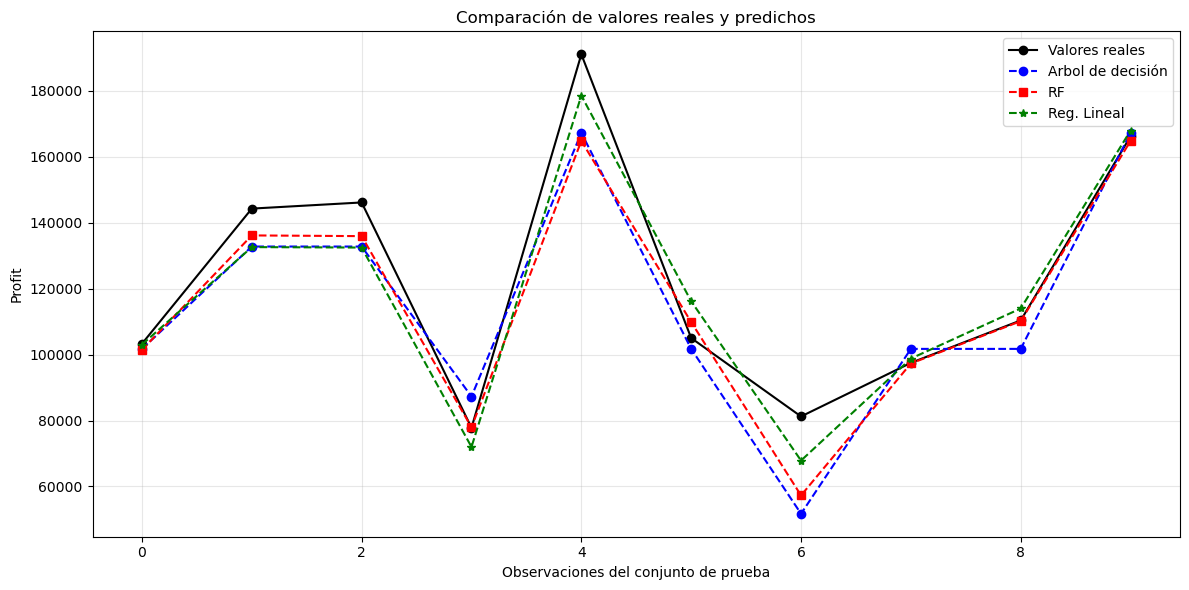

In [71]:
X = np.arange(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(X, np.array(y_test), 'k-o',label='Valores reales')
plt.plot(X, pred_arbol2, 'b--o', label='Arbol de decisión')
plt.plot(X, pred_rf2, 'r--s',label='RF')
plt.plot(X, pred_lineal, 'g--*',label='Reg. Lineal')
plt.xlabel('Observaciones del conjunto de prueba')
plt.ylabel('Profit')
plt.title('Comparación de valores reales y predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Vemos las métricas obtenidas por los modelos seleccionados.

In [74]:
metricas_arbol2 = evaluar_modelo(y_test, pred_arbol2)
mejor_metricas = pd.DataFrame({
    "Lineal": metricas_lineal,
    "Árbol": metricas_arbol2,
    "RF": metricas_rf2
})

display(mejor_metricas.round(2))

,Lineal,Árbol,RF
R2,0.93,0.85,0.89
MAE,7514.29,10643.97,7721.32
RMSE,9137.99,13949.48,12094.45
MAPE,0.06,0.10,0.06
NMAE,0.07,0.09,0.07
NRMSE,0.08,0.12,0.11


Los resultados obtenidos sobre el conjunto de prueba muestran que la regresión lineal presentó el mejor desempeño predictivo, alcanzando un R² de 0.93 y los menores errores MAE (7514.29) y RMSE (9137.99). Esto sugiere que las relaciones entre las variables predictoras y las ganancias (profit) pueden representarse adecuadamente mediante un modelo lineal, sin necesidad de recurrir a algoritmos de mayor complejidad. Random Forest obtuvo el segundo mejor desempeño (R² = 0.89), superando al árbol de decisión individual (R² = 0.85), lo que evidencia las ventajas de combinar múltiples árboles. Sin embargo, ninguno de estos modelos superó a la regresión lineal. Es importante considerar que los hiperparámetros utilizados para controlar el sobreajuste en los modelos basados en árboles fueron establecidos de manera arbitraria, por lo que sus resultados podrían mejorar mediante una búsqueda sistemática de hiperparámetros utilizando validación cruzada.

# Ajustemos hiperparámetros utilizando GridSearchCV